# 6BUIS017W CWK1 - Task 3: Evidence for the business review
This notebook produces the **evidence** (tables and figures) for 3.2.1-3.2.3.

Needs from earlier tasks (upload to `data/`): `features_with_clusters.csv` (Task 2) and `weekly_returns.csv` (Task 1).

| Section | Brief item |
|---|---|
| 1 | 3.2.1 sector composition and risk/return vs RFM clusters |
| 2 | 3.2.2 sensitivity summary (correlations, Monetary removal) |
| 3 | 3.2.3 return dependencies and other limitation evidence |

In [ ]:
from pathlib import Path
Path("data").mkdir(exist_ok=True)
need = ["features_with_clusters.csv", "weekly_returns.csv"]
if not all(Path("data", f).exists() for f in need):
    from google.colab import files
    print("Choose BOTH files in the dialog:", need)
    up = files.upload()
    for name, content in up.items():
        for f in need:
            if name.startswith(f.replace(".csv", "")):          # tolerates browser renames like 'weekly_returns (1).csv'
                Path("data", f).write_bytes(content)
print({f: Path("data", f).exists() for f in need})

Choose BOTH files in the dialog: ['features_with_clusters.csv', 'weekly_returns.csv']


Saving weekly_returns.csv to weekly_returns.csv
{'features_with_clusters.csv': True, 'weekly_returns.csv': True}


In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from sklearn.metrics import adjusted_rand_score
from importlib.metadata import version
for p in ["pandas", "numpy", "scipy", "scikit-learn", "matplotlib"]: print(f"{p:14s}{version(p)}")
DATA, FIG = Path("data"), Path("figures"); FIG.mkdir(exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

d = pd.read_csv(DATA / "features_with_clusters.csv", index_col="Ticker", parse_dates=["Last_Event_Date"])
d = d.rename(columns={"GICS Sector": "Sector"})
SOL = ["Ward_RR", "KMeans_RR", "Ward_RFM", "KMeans_RFM"]
print("Shares:", len(d), "| sectors:", d["Sector"].nunique())
print({s: d[s].nunique() for s in SOL})

pandas        2.2.3
numpy         2.4.6
scipy         1.16.3
scikit-learn  1.6.1
matplotlib    3.10.0
Shares: 485 | sectors: 11
{'Ward_RR': 3, 'KMeans_RR': 3, 'Ward_RFM': 3, 'KMeans_RFM': 3}


## 1. Cluster profiles and sector composition (3.2.1)
### 1.1 Original-unit profiles side by side

In [ ]:
rr = d.groupby("Ward_RR").agg(n=("Weekly_Beta", "size"), return_pct=("Mean_Weekly_Return", lambda s: 100*s.mean()),
                              beta=("Weekly_Beta", "mean"), M_median_bn=("M", lambda s: s.median()/1e9), R_median=("R", "median"), F_mean=("F", "mean")).round(2)
rfm = d.groupby("Ward_RFM").agg(n=("R", "size"), R_median=("R", "median"), F_mean=("F", "mean"), M_median_bn=("M", lambda s: s.median()/1e9),
                                return_pct=("Mean_Weekly_Return", lambda s: 100*s.mean()), beta=("Weekly_Beta", "mean")).round(2)
print("Ward risk & return clusters, with activity measures added for comparison:\n", rr.to_string())
print("\nWard RFM clusters, with risk & return added for comparison:\n", rfm.to_string())
rr.to_csv(DATA / "t3_profile_ward_rr_extended.csv"); rfm.to_csv(DATA / "t3_profile_ward_rfm_extended.csv")

Ward risk & return clusters, with activity measures added for comparison:
            n  return_pct  beta  M_median_bn  R_median  F_mean
Ward_RR                                                      
1        164        0.29  0.60        17.65      11.0    2.78
2        229        0.15  1.11        14.04      11.0    3.05
3         92        0.63  1.30        24.18      11.0    3.20

Ward RFM clusters, with risk & return added for comparison:
             n  R_median  F_mean  M_median_bn  return_pct  beta
Ward_RFM                                                      
1         249      11.0    3.35        11.15        0.26  0.94
2          82      54.5    2.10        17.85        0.29  1.01
3         154      11.0    2.86        39.70        0.34  1.01


### 1.2 How the two segmentations overlap (same shares)

ARI(Ward_RR, Ward_RFM) = 0.024
ARI(KMeans_RR, KMeans_RFM) = 0.019

Counts:
 RFM            1   2   3
Risk/return             
1             80  26  58
2            133  37  59
3             36  19  37

Row %:
 RFM             1     2     3
Risk/return                  
1            48.8  15.9  35.4
2            58.1  16.2  25.8
3            39.1  20.7  40.2


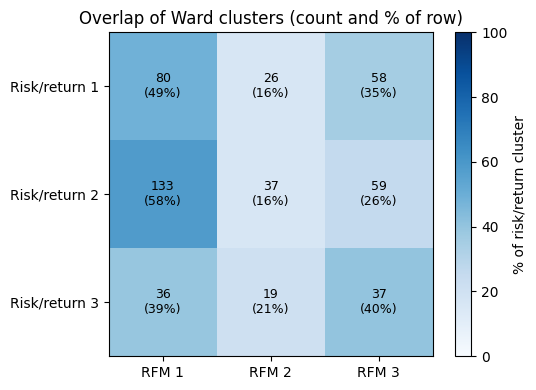

In [ ]:
for a, b in [("Ward_RR", "Ward_RFM"), ("KMeans_RR", "KMeans_RFM")]:
    print(f"ARI({a}, {b}) = {adjusted_rand_score(d[a], d[b]):.3f}")
ct = pd.crosstab(d["Ward_RR"], d["Ward_RFM"], rownames=["Risk/return"], colnames=["RFM"])
print("\nCounts:\n", ct.to_string()); print("\nRow %:\n", (ct.div(ct.sum(1), axis=0)*100).round(1).to_string())
ct.to_csv(DATA / "t3_overlap_ward_rr_vs_rfm.csv")

fig, ax = plt.subplots(figsize=(5.5, 4))
pct = ct.div(ct.sum(1), axis=0)*100
im = ax.imshow(pct.values, cmap="Blues", vmin=0, vmax=100)
for i in range(ct.shape[0]):
    for j in range(ct.shape[1]): ax.text(j, i, f"{ct.values[i, j]}\n({pct.values[i, j]:.0f}%)", ha="center", va="center", fontsize=9)
ax.set_xticks(range(ct.shape[1]), [f"RFM {c}" for c in ct.columns]); ax.set_yticks(range(ct.shape[0]), [f"Risk/return {c}" for c in ct.index])
ax.set_title("Overlap of Ward clusters (count and % of row)"); plt.colorbar(im, label="% of risk/return cluster"); plt.tight_layout()
plt.savefig(FIG / "overlap_rr_vs_rfm.png", dpi=150); plt.show()

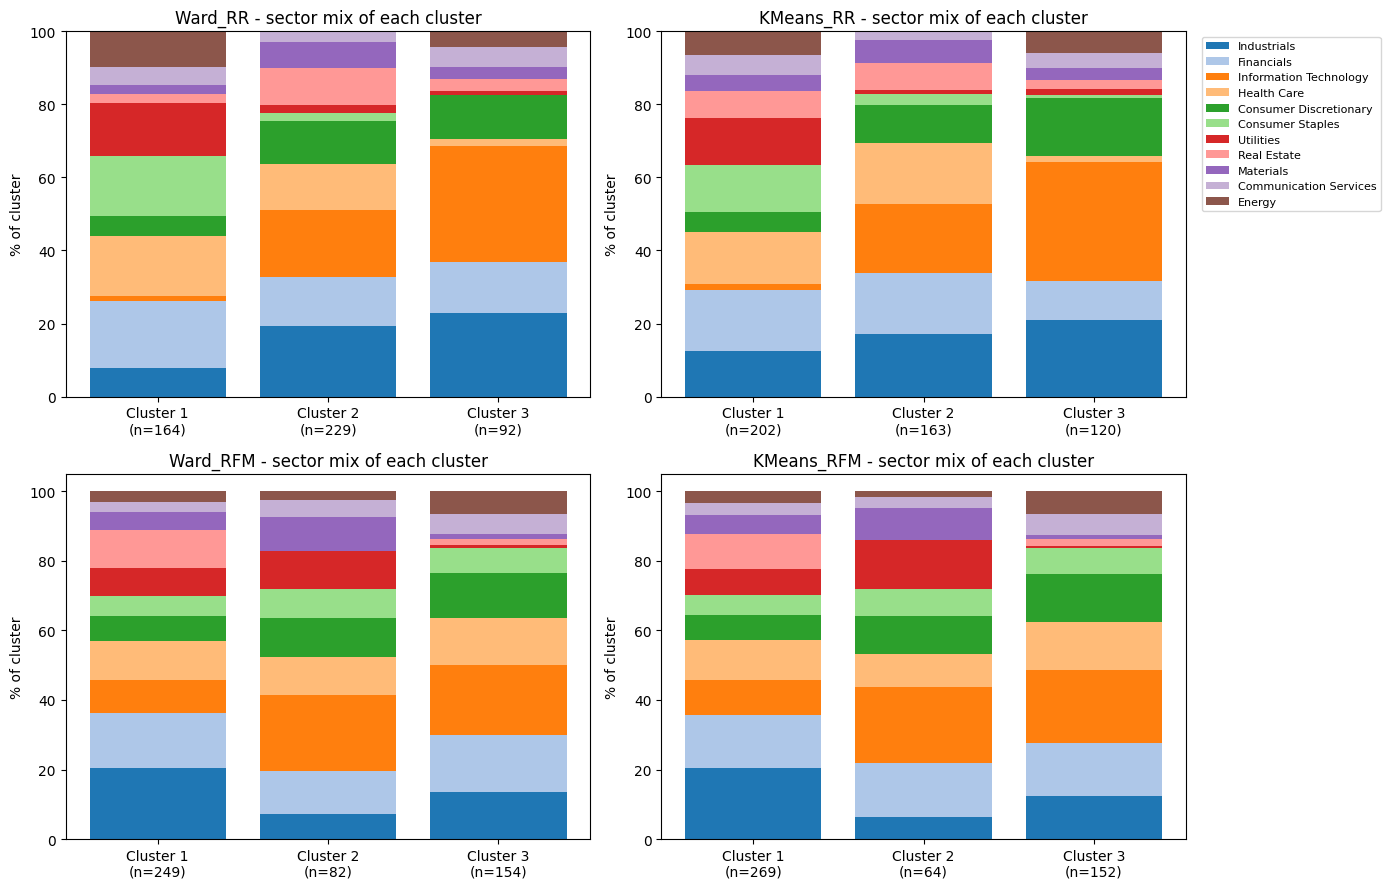

In [ ]:
order = d["Sector"].value_counts().index.tolist()
colors = {s: plt.cm.tab20(i) for i, s in enumerate(order)}
universe = d["Sector"].value_counts(normalize=True).reindex(order) * 100

def sector_pct(col):
    return (pd.crosstab(d["Sector"], d[col], normalize="columns") * 100).reindex(order)

fig, ax = plt.subplots(2, 2, figsize=(14, 9))
for a, col in zip(ax.ravel(), SOL):
    p = sector_pct(col)
    bottom = np.zeros(p.shape[1])
    for s in order:
        a.bar([f"Cluster {c}\n(n={int((d[col]==c).sum())})" for c in p.columns], p.loc[s].values, bottom=bottom, color=colors[s], label=s)
        bottom += p.loc[s].values
    a.set_title(col + " - sector mix of each cluster"); a.set_ylabel("% of cluster")
ax[0, 1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "sector_composition.png", dpi=150); plt.show()

In [ ]:
# Over/under-representation vs the whole universe, in percentage points (Ward solutions)
for col in ["Ward_RR", "Ward_RFM"]:
    diff = (sector_pct(col).sub(universe, axis=0)).round(1)
    print(f"\n{col}: sector share in cluster minus sector share in universe (pp)\n", diff.to_string())
    diff.to_csv(DATA / f"t3_sector_diff_{col}.csv")

# Does sector mix differ by cluster more than chance? (chi-square; Cramer's V = effect size)
rows = []
for col in SOL:
    tab = pd.crosstab(d["Sector"], d[col]); chi2, p, dof, exp = chi2_contingency(tab)
    v = np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1)))
    rows.append(dict(solution=col, chi2=round(chi2, 1), dof=dof, p_value=round(p, 4), cramers_V=round(v, 3), cells_expected_lt5=f"{(exp < 5).mean():.0%}"))
chi = pd.DataFrame(rows).set_index("solution"); print("\n", chi.to_string()); chi.to_csv(DATA / "t3_sector_chi2.csv")


Ward_RR: sector share in cluster minus sector share in universe (pp)
 Ward_RR                    1    2     3
Sector                                 
Industrials             -8.2  3.1   6.7
Financials               3.0 -1.7  -1.1
Information Technology -13.8  3.3  16.5
Health Care              4.5  0.7  -9.8
Consumer Discretionary  -4.2  2.1   2.3
Consumer Staples         9.9 -4.4  -6.6
Utilities                8.4 -4.0  -5.1
Real Estate             -3.7  3.9  -2.9
Materials               -2.3  2.2  -1.5
Communication Services   0.8 -1.1   1.3
Energy                   5.6 -4.1   0.2

Ward_RFM: sector share in cluster minus sector share in universe (pp)
 Ward_RFM                  1    2    3
Sector                               
Industrials             4.4 -8.8 -2.4
Financials              0.4 -3.1  1.0
Information Technology -5.4  6.9  5.1
Health Care            -0.7 -1.0  1.7
Consumer Discretionary -2.5  1.3  3.3
Consumer Staples       -1.0  1.9  0.5
Utilities               1.8  4.8 

In [ ]:
# Sector-level context: what does each sector look like on the raw features?
sec = d.groupby("Sector").agg(n=("Weekly_Beta", "size"), mean_return_pct=("Mean_Weekly_Return", lambda s: 100*s.mean()), mean_beta=("Weekly_Beta", "mean"),
                              M_median_bn=("M", lambda s: s.median()/1e9), R_median=("R", "median"), F_mean=("F", "mean")).round(2).loc[order]
print(sec.to_string()); sec.to_csv(DATA / "t3_sector_context.csv")

                         n  mean_return_pct  mean_beta  M_median_bn  R_median  F_mean
Sector                                                                               
Industrials             78             0.33       1.02        14.57      11.0    3.17
Financials              74             0.32       0.98        16.27      11.0    2.80
Information Technology  73             0.39       1.35        27.79      11.0    2.97
Health Care             58             0.13       0.81        20.03      11.0    3.34
Consumer Discretionary  47             0.34       1.22        21.86      11.0    2.83
Consumer Staples        32             0.10       0.52        17.70      11.0    2.84
Utilities               30             0.23       0.56        11.01      11.0    2.77
Real Estate             30             0.21       0.91         9.03      11.0    3.10
Materials               23             0.20       0.97        13.77      11.0    2.74
Communication Services  20             0.24       0.87

Correlations among R, F, log1p(M):
              R      F  log1p_M
R        1.000 -0.348    0.153
F       -0.348  1.000    0.014
log1p_M  0.153  0.014    1.000

 corr(R,F)                                        -0.348
corr(R,log1p M)                                   0.153
corr(F,log1p M)                                   0.014
ARI full RFM vs R+F only (Ward)                   0.291
ARI Ward vs K-means (RFM)                         0.833
ARI Ward vs K-means (risk/return)                 0.511
ARI risk/return vs RFM (Ward)                     0.024
share of log1p(M) variance explained: full RFM    0.516
share of log1p(M) variance explained: R+F only    0.004

Traded value by cluster
           full RFM: median M ($bn)  full RFM: n
Ward_RFM                                       
1                            11.15          249
2                            17.85           82
3                            39.70          154 

               R+F only: median M ($bn)  R+F only: n
Ward_RF_only 

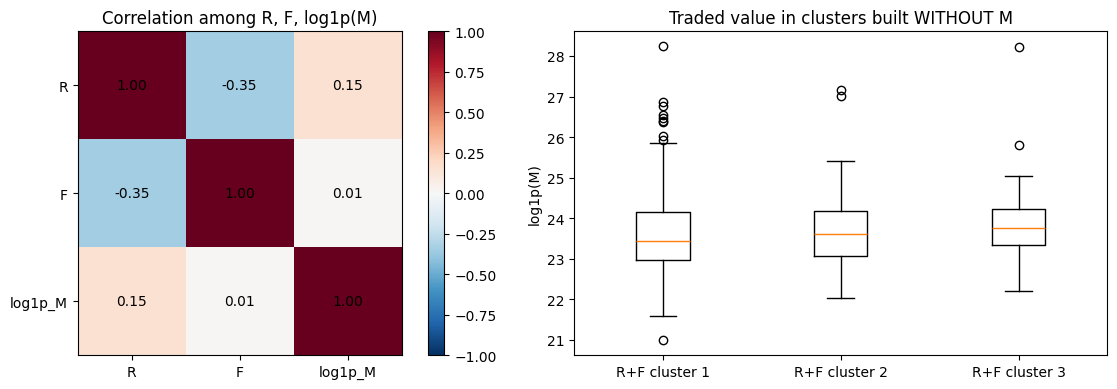

In [ ]:
X = pd.DataFrame({"R": d["R"], "F": d["F"], "log1p_M": np.log1p(d["M"])})
corr = X.corr(); print("Correlations among R, F, log1p(M):\n", corr.round(3).to_string())

def eta_sq(col):
    y = np.log1p(d["M"]); ssw = sum(((y[g.index] - y[g.index].mean())**2).sum() for _, g in d.groupby(col))
    return 1 - ssw / ((y - y.mean())**2).sum()

sens = pd.Series({
    "corr(R,F)": corr.loc["R", "F"], "corr(R,log1p M)": corr.loc["R", "log1p_M"], "corr(F,log1p M)": corr.loc["F", "log1p_M"],
    "ARI full RFM vs R+F only (Ward)": adjusted_rand_score(d["Ward_RFM"], d["Ward_RF_only"]),
    "ARI Ward vs K-means (RFM)": adjusted_rand_score(d["Ward_RFM"], d["KMeans_RFM"]),
    "ARI Ward vs K-means (risk/return)": adjusted_rand_score(d["Ward_RR"], d["KMeans_RR"]),
    "ARI risk/return vs RFM (Ward)": adjusted_rand_score(d["Ward_RR"], d["Ward_RFM"]),
    "share of log1p(M) variance explained: full RFM": eta_sq("Ward_RFM"),
    "share of log1p(M) variance explained: R+F only": eta_sq("Ward_RF_only")}).round(3)
print("\n", sens.to_string()); sens.to_csv(DATA / "t3_sensitivity_summary.csv", header=["value"])

tv = pd.DataFrame({"full RFM: median M ($bn)": d.groupby("Ward_RFM")["M"].median()/1e9, "full RFM: n": d.groupby("Ward_RFM").size()}).round(2)
tv2 = pd.DataFrame({"R+F only: median M ($bn)": d.groupby("Ward_RF_only")["M"].median()/1e9, "R+F only: n": d.groupby("Ward_RF_only").size()}).round(2)
print("\nTraded value by cluster\n", tv.to_string(), "\n\n", tv2.to_string())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
im = ax[0].imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
for i in range(3):
    for j in range(3): ax[0].text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center")
ax[0].set_xticks(range(3), corr.columns); ax[0].set_yticks(range(3), corr.index); ax[0].set_title("Correlation among R, F, log1p(M)"); plt.colorbar(im, ax=ax[0])
data = [np.log1p(d.loc[d["Ward_RF_only"] == c, "M"]) for c in sorted(d["Ward_RF_only"].unique())]
ax[1].boxplot(data); ax[1].set_xticks(range(1, len(data) + 1), [f"R+F cluster {c}" for c in sorted(d["Ward_RF_only"].unique())]); ax[1].set_ylabel("log1p(M)")
ax[1].set_title("Traded value in clusters built WITHOUT M")
plt.tight_layout(); plt.savefig(FIG / "sensitivity_summary.png", dpi=150); plt.show()

## 3. Critical evaluation evidence (3.2.3)
### 3.1 Return dependencies - does a risk/return cluster mean diversification?
Shares in the same beta/return cluster might still move together. Below: average pairwise correlation of weekly returns **within** each cluster and **between** clusters, and the same after removing each share's market component (residuals).

In [ ]:
w = pd.read_csv(DATA / "weekly_returns.csv", index_col=0, parse_dates=True)
mkt = w["^GSPC"]; w = w[d.index]                      # same shares, same weeks
print("Weekly return matrix:", w.shape)

resid = pd.DataFrame({t: w[t] - d.loc[t, "Weekly_Beta"] * mkt for t in w.columns})   # return minus beta x market return

def block_corr(R, col):
    C = R.corr().values; lab = d[col].values; ks = sorted(np.unique(lab)); M = pd.DataFrame(index=ks, columns=ks, dtype=float)
    for a in ks:
        for b in ks:
            ia, ib = np.where(lab == a)[0], np.where(lab == b)[0]; blk = C[np.ix_(ia, ib)]
            M.loc[a, b] = ((blk.sum() - len(ia)) / (len(ia) * (len(ia) - 1)) if len(ia) > 1 else np.nan) if a == b else blk.mean()   # exclude self-correlation on the diagonal
    return M.round(3)

C_all = w.corr().values; off = C_all[np.triu_indices_from(C_all, 1)]
print(f"Average pairwise correlation, ALL shares: raw {off.mean():.3f}; after removing beta x market: {resid.corr().values[np.triu_indices_from(C_all, 1)].mean():.3f}")
for col in ["Ward_RR", "Ward_RFM"]:
    print(f"\n{col}: mean pairwise correlation (rows/cols = clusters; diagonal = within)\nRaw returns:\n", block_corr(w, col).to_string(),
          "\nAfter removing beta x market:\n", block_corr(resid, col).to_string())
block_corr(w, "Ward_RR").to_csv(DATA / "t3_paircorr_ward_rr_raw.csv"); block_corr(resid, "Ward_RR").to_csv(DATA / "t3_paircorr_ward_rr_resid.csv")

Weekly return matrix: (207, 485)
Average pairwise correlation, ALL shares: raw 0.300; after removing beta x market: 0.052

Ward_RR: mean pairwise correlation (rows/cols = clusters; diagonal = within)
Raw returns:
        1      2      3
1  0.281  0.257  0.224
2  0.257  0.364  0.348
3  0.224  0.348  0.374 
After removing beta x market:
        1      2      3
1  0.146  0.042 -0.009
2  0.042  0.068  0.033
3 -0.009  0.033  0.061

Ward_RFM: mean pairwise correlation (rows/cols = clusters; diagonal = within)
Raw returns:
        1      2      3
1  0.329  0.294  0.296
2  0.294  0.266  0.273
3  0.296  0.273  0.284 
After removing beta x market:
        1      2      3
1  0.088  0.056  0.040
2  0.056  0.036  0.028
3  0.040  0.028  0.022


In [ ]:
# Same-sector shares vs different-sector shares: are dependencies explained by sector, not by beta clusters?
C = w.corr(); sec = d["Sector"].values
n = len(sec)
iu = np.triu_indices(n, 1); same_mask = sec[iu[0]] == sec[iu[1]]
vals = C.values[iu]
Cr = resid.corr().values[iu]
print(f"Mean pairwise correlation, same sector: raw {vals[same_mask].mean():.3f} | residual {Cr[same_mask].mean():.3f}")
print(f"Mean pairwise correlation, different sector: raw {vals[~same_mask].mean():.3f} | residual {Cr[~same_mask].mean():.3f}")

Mean pairwise correlation, same sector: raw 0.414 | residual 0.173
Mean pairwise correlation, different sector: raw 0.285 | residual 0.037


In [ ]:
mode_date = d["Last_Event_Date"].mode()[0]
share_mode = (d["Last_Event_Date"] == mode_date).mean()
print(f"{(d['Last_Event_Date'] == mode_date).sum()} of {len(d)} shares ({share_mode:.0%}) have the same latest high-volume date: {mode_date.date()}")
print("Share of shares with F = 0 in the last 60 sessions:", f"{(d['F'] == 0).mean():.1%}", f"({(d['F']==0).sum()} shares)")
print("Top 5 shares by traded value M ($bn):\n", (d["M"].sort_values(ascending=False).head(5) / 1e9).round(0).to_string())
print(f"\nTop 10 shares hold {d['M'].sort_values(ascending=False).head(10).sum() / d['M'].sum():.0%} of total traded value in the sample")

353 of 485 shares (73%) have the same latest high-volume date: 2024-12-20
Share of shares with F = 0 in the last 60 sessions: 2.1% (10 shares)
Top 5 shares by traded value M ($bn):
 Ticker
TSLA    1848.0
NVDA    1825.0
AAPL     623.0
MSFT     535.0
AMZN     468.0

Top 10 shares hold 36% of total traded value in the sample


In [ ]:
import shutil
try:
    from google.colab import files
    shutil.make_archive("task3_outputs", "zip", ".", "data"); shutil.make_archive("task3_figures", "zip", ".", "figures")
    files.download("task3_outputs.zip"); files.download("task3_figures.zip")
except ImportError:
    print("Not in Colab - outputs are in data/ and figures/.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>